# Crop Burn Detection — Fine-tuning LFM2.5-VL-450M

Fine-tunes Liquid AI's **LFM2.5-VL-450M** vision-language model on labeled Sentinel-2 crop burn imagery.

**Pipeline:**  
`[RGB image] + [SWIR image]` → model → `{burn_detected, severity, fraction, freshness, ...}`

**GPU requirements:**
| GPU | VRAM | Config |
|-----|------|--------|
| RTX A4000 / 3090 | 16 GB | batch=1, grad_accum=16, LoRA r=16 ✅ this notebook |
| A100 40 GB | 40 GB | batch=4, grad_accum=4, LoRA r=32 |
| A100 80 GB | 80 GB | batch=8, grad_accum=2, full fine-tune |

**Why LoRA instead of full fine-tune on 16GB:**  
LFM2.5-VL-450M in 4-bit + LoRA adapters peaks at ~10-12GB VRAM, comfortably inside the A4000 budget. We still target attention + MLP layers so the SWIR patch semantics get updated.

## 1. Install Dependencies

In [1]:
%%capture
!pip install -q \
    "transformers>=5.1.0" \
    "trl>=0.12.0" \
    "peft>=0.14.0" \
    "datasets>=3.0.0" \
    "accelerate>=1.0.0" \
    pillow \
    huggingface_hub \
    matplotlib \
    pandas

## 2. Configuration

In [2]:
import os, json, torch
from pathlib import Path

# ── Model / data ────────────────────────────────────────────────
BASE_MODEL_ID = "LiquidAI/LFM2.5-VL-450M"
DATASET_ID    = "munish0838/crop-burn-detection-labeled"
OUTPUT_DIR    = "./outputs/crop-burn-lfm"
HF_PUSH_REPO  = "munish0838/crop-burn-detector-v2"

# ── Training (A4000 16GB defaults) ─────────────────────────────
NUM_EPOCHS    = 5
BATCH_SIZE    = 1
GRAD_ACCUM    = 16
LEARNING_RATE = 2e-5
SKIP_CLOUDY   = True   # drop image_quality_limited tiles from train AND eval

# ── Sequence length ─────────────────────────────────────────────
# 2 images × ~256 patch tokens each = 512 image tokens alone.
# Add system prompt (~55), user text (~150), assistant (~50) → ~767 total.
# 512 was too small — truncation cut image tokens, causing the
# "Image features and image tokens do not match" error.
MAX_SEQ_LEN   = 2048

# ── LoRA ───────────────────────────────────────────────────────
LORA_R        = 32
LORA_ALPHA    = 32
LORA_DROPOUT  = 0.05

# ── Output schema: 5 fields, all boolean/categorical ────────────
OUTPUT_FIELDS = [
    "burn_detected",
    "burn_severity",
    "active_smoke_visible",
    "vegetation_phase",
    "image_quality_limited",
]

SYSTEM_PROMPT = (
    "You are an expert in analyzing Sentinel-2 satellite imagery for crop residue "
    "burning detection in northern India. You analyze pairs of RGB and SWIR composites "
    "of 5km tiles and produce structured JSON assessments."
)

USER_PROMPT = """The following two images show the same 5km × 5km tile of agricultural land at the same date.

Image 1 is the RGB composite (B4-B3-B2, natural color).
Image 2 is the SWIR composite (B12-B8-B4 false color), which highlights vegetation moisture, burn scars, and active fires.

In the SWIR composite:
  - Bright green = healthy standing crop (high NIR)
  - Brownish / pinkish-brown = harvested stubble or bare soil
  - Charcoal black or dark brownish-red with rectangular edges = burn scars
  - White or bright cyan = cloud cover
  - Solid black = water or missing data

Analyze both images and output exactly this JSON with no additional text:

{
  "burn_detected": <true|false>,
  "burn_severity": <"none"|"low"|"moderate"|"high">,
  "active_smoke_visible": <true|false>,
  "vegetation_phase": <"pre_harvest"|"harvest_in_progress"|"post_harvest"|"fallow">,
  "image_quality_limited": <true|false>
}"""

print(f"Model      : {BASE_MODEL_ID}")
print(f"Dataset    : {DATASET_ID}")
print(f"Fields     : {OUTPUT_FIELDS}")
print(f"MAX_SEQ_LEN: {MAX_SEQ_LEN}")
print(f"SKIP_CLOUDY: {SKIP_CLOUDY}")
if torch.cuda.is_available():
    vram = torch.cuda.get_device_properties(0).total_memory / 1e9
    print(f"GPU        : {torch.cuda.get_device_name(0)}  ({vram:.1f} GB VRAM)")

Model      : LiquidAI/LFM2.5-VL-450M
Dataset    : munish0838/crop-burn-detection-labeled
Fields     : ['burn_detected', 'burn_severity', 'active_smoke_visible', 'vegetation_phase', 'image_quality_limited']
MAX_SEQ_LEN: 2048
SKIP_CLOUDY: True
GPU        : NVIDIA RTX A4000  (16.9 GB VRAM)


## 3. Load & Explore Dataset

Loading munish0838/crop-burn-detection-labeled ...


data/train-00000-of-00002.parquet:   0%|          | 0.00/392M [00:00<?, ?B/s]

data/train-00001-of-00002.parquet:   0%|          | 0.00/392M [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/200M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/1098 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/267 [00:00<?, ? examples/s]

Filter:   0%|          | 0/1098 [00:00<?, ? examples/s]

Filter:   0%|          | 0/267 [00:00<?, ? examples/s]

Dropped cloudy — train: 1098→685  test: 267→178
Train: 685 | Test: 178


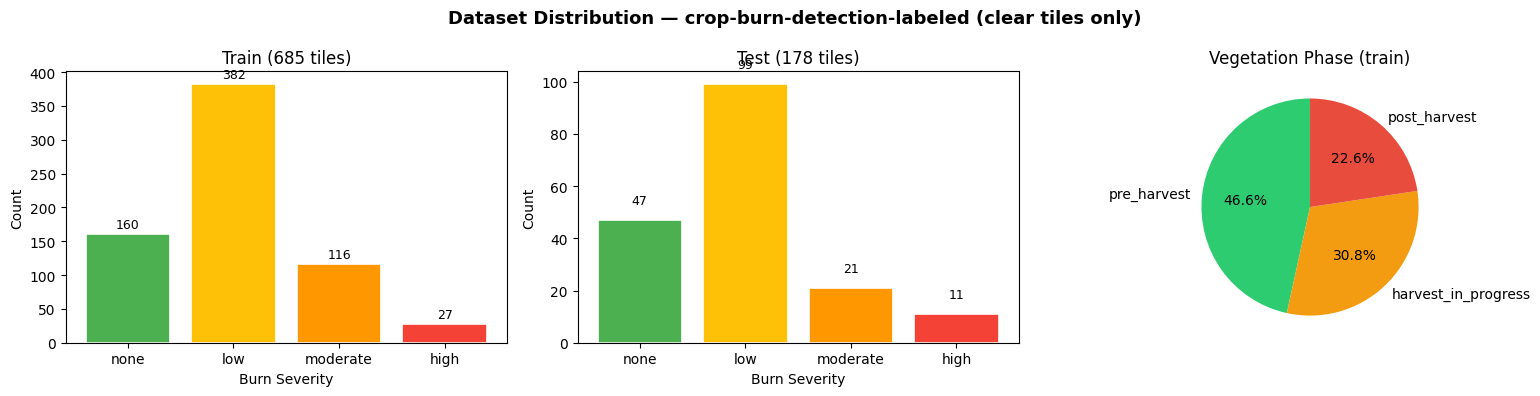

In [3]:
from datasets import load_dataset
import matplotlib.pyplot as plt
import pandas as pd
from collections import Counter

print(f"Loading {DATASET_ID} ...")
ds = load_dataset(DATASET_ID, download_mode="force_redownload")
train_ds, test_ds = ds["train"], ds["test"]

if SKIP_CLOUDY:
    n_train0, n_test0 = len(train_ds), len(test_ds)
    train_ds = train_ds.filter(lambda x: not x["image_quality_limited"])
    test_ds  = test_ds.filter(lambda x: not x["image_quality_limited"])
    print(f"Dropped cloudy — train: {n_train0}→{len(train_ds)}  test: {n_test0}→{len(test_ds)}")

print(f"Train: {len(train_ds)} | Test: {len(test_ds)}")

# ── Dataset distribution chart ──────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
fig.suptitle("Dataset Distribution — crop-burn-detection-labeled"
             + (" (clear tiles only)" if SKIP_CLOUDY else ""),
             fontsize=13, fontweight="bold")

for ax, split, split_ds in zip(axes[:2], ["Train", "Test"], [train_ds, test_ds]):
    burn_counts = Counter(split_ds["burn_severity"])
    labels = ["none", "low", "moderate", "high"]
    vals   = [burn_counts.get(l, 0) for l in labels]
    colors = ["#4CAF50", "#FFC107", "#FF9800", "#F44336"]
    bars = ax.bar(labels, vals, color=colors, edgecolor="white", linewidth=1.2)
    ax.set_title(f"{split} ({len(split_ds)} tiles)")
    ax.set_xlabel("Burn Severity")
    ax.set_ylabel("Count")
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
                str(v), ha="center", va="bottom", fontsize=9)

phase_counts = Counter(train_ds["vegetation_phase"])
axes[2].pie(
    phase_counts.values(), labels=phase_counts.keys(),
    autopct="%1.1f%%", startangle=90,
    colors=["#2ecc71", "#f39c12", "#e74c3c", "#95a5a6"]
)
axes[2].set_title("Vegetation Phase (train)")
plt.tight_layout()
plt.savefig("dataset_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

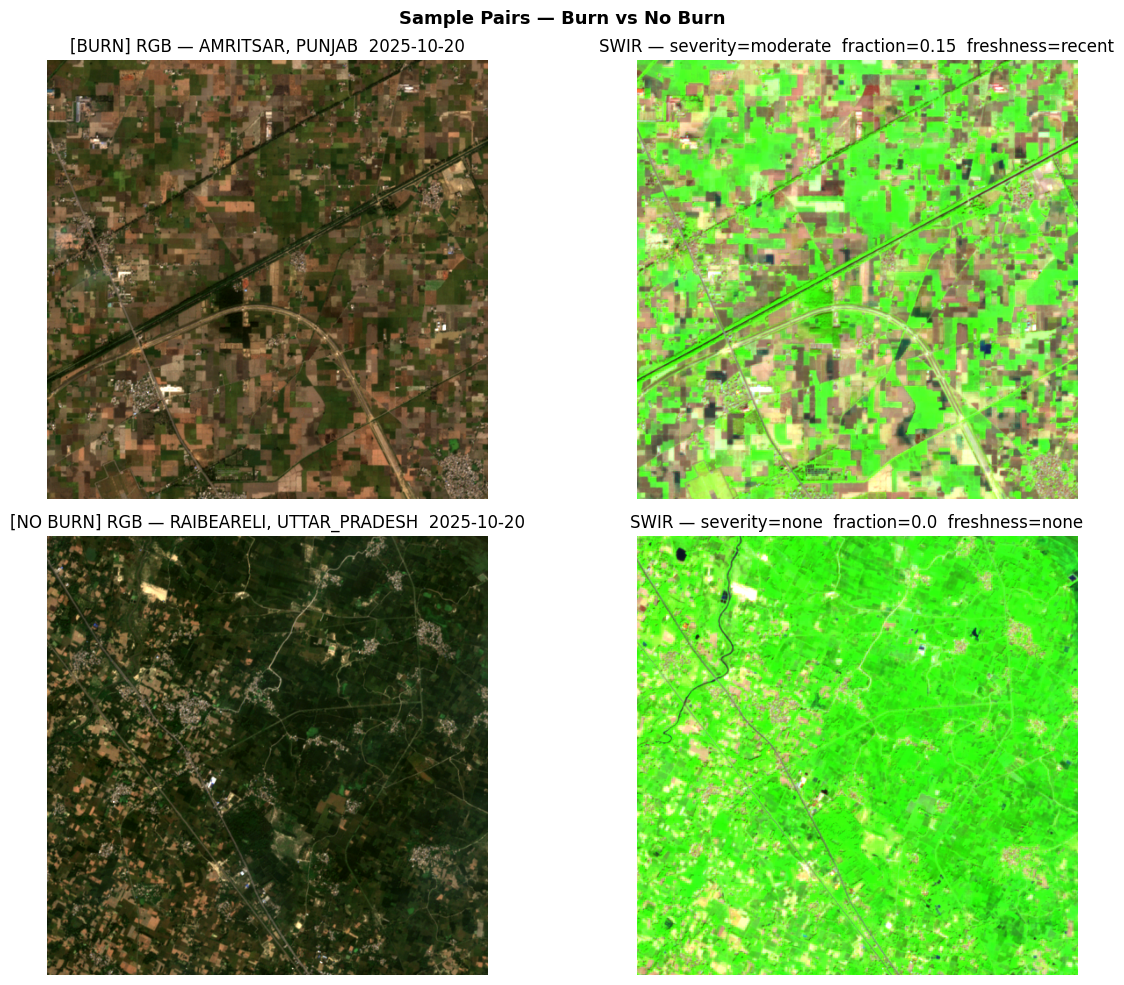

In [4]:
# Visualise burn vs no-burn sample pairs
import random

burn_idx    = random.choice([i for i, x in enumerate(train_ds["burn_detected"]) if x])
no_burn_idx = random.choice([i for i, x in enumerate(train_ds["burn_detected"]) if not x])

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
fig.suptitle("Sample Pairs — Burn vs No Burn", fontsize=13, fontweight="bold")

for row, (idx, label) in enumerate([(burn_idx, "BURN"), (no_burn_idx, "NO BURN")]):
    s   = train_ds[idx]
    ann = json.loads(s["annotation_json"])

    axes[row, 0].imshow(s["rgb_image"])
    axes[row, 0].set_title(f"[{label}] RGB — {s['district']}, {s['state']}  {s['date']}")
    axes[row, 0].axis("off")

    axes[row, 1].imshow(s["swir_image"])
    axes[row, 1].set_title(
        f"SWIR — severity={ann['burn_severity']}  "
        f"fraction={ann['burn_fraction_estimate']}  "
        f"freshness={ann['burn_freshness']}"
    )
    axes[row, 1].axis("off")

plt.tight_layout()
plt.savefig("sample_pairs.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Load Model + Processor

In [5]:
from transformers import AutoProcessor, AutoModelForImageTextToText

# LFM2.5-VL-450M in bf16 = ~900 MB — no quantization needed on a 16 GB GPU.
# We skip BitsAndBytes entirely; it causes set_submodule errors on this model class.
print(f"Loading {BASE_MODEL_ID} in bf16 ...")
model = AutoModelForImageTextToText.from_pretrained(
    BASE_MODEL_ID,
    device_map="auto",
    torch_dtype=torch.bfloat16,
    trust_remote_code=True,
)
processor = AutoProcessor.from_pretrained(BASE_MODEL_ID, trust_remote_code=True)

if processor.tokenizer.pad_token is None:
    processor.tokenizer.pad_token = processor.tokenizer.eos_token
    model.config.pad_token_id = model.config.eos_token_id

total = sum(p.numel() for p in model.parameters())
print(f"Parameters : {total/1e6:.0f}M")
if torch.cuda.is_available():
    used = torch.cuda.memory_allocated() / 1e9
    print(f"VRAM after load : {used:.1f} GB  (headroom for LoRA + activations: {torch.cuda.get_device_properties(0).total_memory/1e9 - used:.1f} GB)")

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading LiquidAI/LFM2.5-VL-450M in bf16 ...


Loading weights:   0%|          | 0/349 [00:00<?, ?it/s]

Parameters : 449M
VRAM after load : 0.9 GB  (headroom for LoRA + activations: 16.0 GB)


## 5. Apply QLoRA

In [6]:
from peft import LoraConfig, get_peft_model

# No prepare_model_for_kbit_training — that's only needed for BitsAndBytes QLoRA.
# For a bf16 model we apply LoRA directly.
lora_cfg = LoraConfig(                                                                                                                                      
      r=LORA_R,   
      lora_alpha=LORA_ALPHA,
      lora_dropout=LORA_DROPOUT,                                                                                                                              
      bias="none",
      task_type="CAUSAL_LM",                                                                                                                                  
      target_modules=[
          # Vision tower attention
          "q_proj", "k_proj", "v_proj", "out_proj",                                                                                                           
          # Vision tower MLP
          "fc1", "fc2",                                                                                                                                       
          # Multi-modal projector — maps SWIR features into language space
          "linear_1", "linear_2",                                                                                                                             
          # Language model feed-forward
          "w1", "w2", "w3",                                                                                                                                   
      ],                                                                                                                                                      
  )
model = get_peft_model(model, lora_cfg)
model.print_trainable_parameters()

trainable params: 16,252,928 || all params: 464,971,776 || trainable%: 3.4955


In [7]:
seen = set()                                                                                                                                                
for name, module in model.named_modules():
  if isinstance(module, torch.nn.Linear):
      leaf = name.split('.')[-1]                                                                                                                          
      if leaf not in seen:
          seen.add(leaf)                                                                                                                                  
          print(leaf, '|', name)

patch_embedding | base_model.model.model.vision_tower.embeddings.patch_embedding
base_layer | base_model.model.model.vision_tower.encoder.layers.0.self_attn.k_proj.base_layer
default | base_model.model.model.vision_tower.encoder.layers.0.self_attn.k_proj.lora_A.default
in_proj | base_model.model.model.language_model.layers.0.conv.in_proj
lm_head | base_model.model.lm_head


## 6. Data Collator

In [8]:
from PIL import Image as PILImage

# ── Canonical image size ────────────────────────────────────────────────────
_sz   = getattr(processor.image_processor, "size", {})
IMG_H = int(getattr(_sz, "height",        None) or getattr(_sz, "shortest_edge", None) or 336)
IMG_W = int(getattr(_sz, "width",         None) or getattr(_sz, "shortest_edge", None) or 336)
print(f"Processor canonical size : {IMG_W}×{IMG_H}")


def build_messages(rgb_img, swir_img, annotation_json_str):
    ann    = json.loads(annotation_json_str)
    target = {f: ann[f] for f in OUTPUT_FIELDS if f in ann}
    return [
        {"role": "system", "content": SYSTEM_PROMPT},
        {
            "role": "user",
            "content": [
                {"type": "image", "image": rgb_img},
                {"type": "image", "image": swir_img},
                {"type": "text",  "text": USER_PROMPT},
            ],
        },
        {"role": "assistant", "content": json.dumps(target)},
    ]


def collate_fn(examples):
    per_sample = []
    for ex in examples:
        rgb  = ex["rgb_image"].resize((IMG_W, IMG_H), PILImage.LANCZOS)
        swir = ex["swir_image"].resize((IMG_W, IMG_H), PILImage.LANCZOS)
        msgs = build_messages(rgb, swir, ex["annotation_json"])

        # Single-pass tokenization — tokenizer and image processor share state
        # so image token count always matches vision encoder feature count.
        inp = processor.apply_chat_template(
            msgs,
            tokenize=True,
            add_generation_prompt=False,
            return_tensors="pt",
            return_dict=True,
        )
        per_sample.append(inp)

    # ── Pad to longest sequence in batch (NO hard truncation) ────────────────
    # Truncating to MAX_SEQ_LEN was the root cause: with 2 images × ~256 patch
    # tokens = 512 image tokens, a 512-token cap cuts off image tokens from the
    # text side, so features (512) > tokens remaining after truncation.
    pad_id  = processor.tokenizer.pad_token_id
    max_len = max(s["input_ids"].shape[1] for s in per_sample)

    input_ids_padded = torch.full((len(per_sample), max_len), pad_id, dtype=torch.long)
    attention_padded = torch.zeros((len(per_sample), max_len), dtype=torch.long)

    for i, s in enumerate(per_sample):
        L = s["input_ids"].shape[1]
        input_ids_padded[i, :L] = s["input_ids"][0]
        attention_padded[i, :L] = s["attention_mask"][0]

    batch = {"input_ids": input_ids_padded, "attention_mask": attention_padded}

    for key in per_sample[0]:
        if key in ("input_ids", "attention_mask"):
            continue
        try:
            batch[key] = torch.cat([s[key] for s in per_sample], dim=0)
        except Exception:
            pass

    labels = batch["input_ids"].clone()
    labels[labels == pad_id] = -100
    batch["labels"] = labels
    return batch


# Smoke-test
sample_batch = collate_fn([train_ds[0]])
seq_len = sample_batch["input_ids"].shape[1]
print(f"input_ids    : {sample_batch['input_ids'].shape}  (seq_len={seq_len}, fits in MAX_SEQ_LEN={MAX_SEQ_LEN}: {seq_len <= MAX_SEQ_LEN})")
print(f"labels       : {sample_batch['labels'].shape}")
if "pixel_values" in sample_batch:
    print(f"pixel_values : {sample_batch['pixel_values'].shape}")

msgs_check = build_messages(
    train_ds[0]["rgb_image"], train_ds[0]["swir_image"], train_ds[0]["annotation_json"]
)
print(f"\nTraining target : {msgs_check[2]['content']}")
assert "notes" not in msgs_check[2]["content"]
print("Collator OK")

Processor canonical size : 512×512
input_ids    : torch.Size([1, 881])  (seq_len=881, fits in MAX_SEQ_LEN=2048: True)
labels       : torch.Size([1, 881])
pixel_values : torch.Size([2, 1024, 768])

Training target : {"burn_detected": false, "burn_severity": "none", "active_smoke_visible": false, "vegetation_phase": "pre_harvest", "image_quality_limited": false}
Collator OK


## 7. Train

In [9]:
from transformers import TrainingArguments, Trainer
import torch.nn as nn

# ── Class-balanced loss ────────────────────────────────────────────────────
burn_token_id    = processor.tokenizer.encode("true",  add_special_tokens=False)[0]
no_burn_token_id = processor.tokenizer.encode("false", add_special_tokens=False)[0]
burn_fraction    = 0.65
no_burn_weight   = burn_fraction / (1 - burn_fraction)   # ≈ 1.86

# get_output_embeddings() returns the lm_head regardless of PEFT wrapping,
# and its weight.shape[0] is the padded vocab size the logits will have.
# This avoids AttributeError on Lfm2VlConfig (no vocab_size) and the
# shape mismatch from len(tokenizer) (64400 vs padded 65536).
vocab_size    = model.get_output_embeddings().weight.shape[0]
token_weights = torch.ones(vocab_size, dtype=torch.float)
token_weights[no_burn_token_id] = no_burn_weight
print(f"Logit vocab size : {vocab_size}  |  tokenizer : {len(processor.tokenizer)}")
print(f"'true'({burn_token_id}) → 1.0   'false'({no_burn_token_id}) → {no_burn_weight:.2f}")


class BalancedTrainer(Trainer):
    """Cross-entropy with per-token weights to counter burn-class dominance."""
    def __init__(self, *args, token_weights=None, **kwargs):
        super().__init__(*args, **kwargs)
        self._token_weights = token_weights

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits  = outputs.logits
        shift_logits = logits[:, :-1].contiguous()
        shift_labels = labels[:, 1:].contiguous()
        weight = self._token_weights.to(shift_logits.device) if self._token_weights is not None else None
        loss = nn.functional.cross_entropy(
            shift_logits.view(-1, shift_logits.size(-1)),
            shift_labels.view(-1),
            weight=weight,
            ignore_index=-100,
        )
        return (loss, outputs) if return_outputs else loss


args = TrainingArguments(
    output_dir=OUTPUT_DIR,
    num_train_epochs=NUM_EPOCHS,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,
    gradient_accumulation_steps=GRAD_ACCUM,
    learning_rate=LEARNING_RATE,
    warmup_ratio=0.05,
    lr_scheduler_type="cosine",
    bf16=True,
    logging_steps=10,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,
    load_best_model_at_end=True,
    dataloader_num_workers=2,
    report_to="none",
    gradient_checkpointing=True,
    remove_unused_columns=False,
)

trainer = BalancedTrainer(
    model=model,
    args=args,
    train_dataset=train_ds,
    eval_dataset=test_ds,
    data_collator=collate_fn,
    token_weights=token_weights,
)

print("Starting training...")
train_result = trainer.train()
print("Training complete.")
print(train_result.metrics)

[transformers] warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


Logit vocab size : 65536  |  tokenizer : 64400
'true'(10567) → 1.0   'false'(13890) → 1.86
Starting training...


[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.
/usr/local/lib/python3.11/dist-packages/torch/utils/checkpoint.py:1399: FutureWarning: `torch.cpu.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cpu', args...)` instead.
  with device_autocast_ctx, torch.cpu.amp.autocast(**cpu_autocast_kwargs), recompute_context:  # type: ignore[attr-defined]


Epoch,Training Loss,Validation Loss
1,91.438196,3.657038
2,12.390268,0.565488
3,3.485550,0.161516
4,1.935540,0.117649
5,1.754058,0.110045


/usr/local/lib/python3.11/dist-packages/torch/utils/checkpoint.py:1399: FutureWarning: `torch.cpu.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cpu', args...)` instead.
  with device_autocast_ctx, torch.cpu.amp.autocast(**cpu_autocast_kwargs), recompute_context:  # type: ignore[attr-defined]
/usr/local/lib/python3.11/dist-packages/torch/utils/checkpoint.py:1399: FutureWarning: `torch.cpu.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cpu', args...)` instead.
  with device_autocast_ctx, torch.cpu.amp.autocast(**cpu_autocast_kwargs), recompute_context:  # type: ignore[attr-defined]
/usr/local/lib/python3.11/dist-packages/torch/utils/checkpoint.py:1399: FutureWarning: `torch.cpu.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cpu', args...)` instead.
  with device_autocast_ctx, torch.cpu.amp.autocast(**cpu_autocast_kwargs), recompute_context:  # type: ignore[attr-defined]
/usr/local/lib/python3.11/dist-packages/torch/uti

Training complete.
{'train_runtime': 996.0412, 'train_samples_per_second': 3.439, 'train_steps_per_second': 0.216, 'total_flos': 7204854469263360.0, 'train_loss': 30.414019491506178, 'epoch': 5.0}


## 8. Training Loss Curves

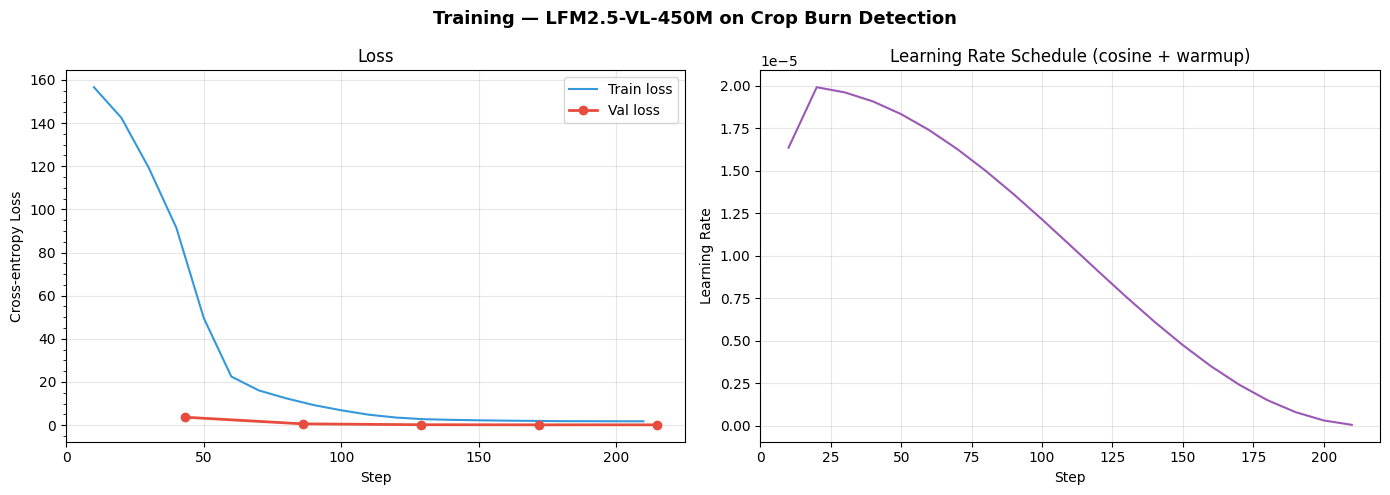

Final train loss : 1.7541
Final val loss   : 0.1100


In [10]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

log_history = trainer.state.log_history

train_steps  = [e["step"]     for e in log_history if "loss" in e and "eval_loss" not in e]
train_loss   = [e["loss"]     for e in log_history if "loss" in e and "eval_loss" not in e]
eval_steps   = [e["step"]     for e in log_history if "eval_loss" in e]
eval_loss    = [e["eval_loss"]for e in log_history if "eval_loss" in e]
lr_steps     = [e["step"]     for e in log_history if "learning_rate" in e]
lr_vals      = [e["learning_rate"] for e in log_history if "learning_rate" in e]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Training — LFM2.5-VL-450M on Crop Burn Detection", fontsize=13, fontweight="bold")

# Loss curves
ax1.plot(train_steps, train_loss, label="Train loss", color="#3498db", linewidth=1.5)
ax1.plot(eval_steps,  eval_loss,  label="Val loss",   color="#e74c3c",
         linewidth=2, marker="o", markersize=6)
ax1.set_xlabel("Step")
ax1.set_ylabel("Cross-entropy Loss")
ax1.set_title("Loss")
ax1.legend()
ax1.grid(alpha=0.3)
ax1.yaxis.set_minor_locator(ticker.AutoMinorLocator())

# LR schedule
ax2.plot(lr_steps, lr_vals, color="#9b59b6", linewidth=1.5)
ax2.set_xlabel("Step")
ax2.set_ylabel("Learning Rate")
ax2.set_title("Learning Rate Schedule (cosine + warmup)")
ax2.grid(alpha=0.3)
ax2.ticklabel_format(style="sci", axis="y", scilimits=(0, 0))

plt.tight_layout()
plt.savefig("training_curves.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Final train loss : {train_loss[-1]:.4f}")
print(f"Final val loss   : {eval_loss[-1]:.4f}")

## 9. Save, Merge, and Push to Hub

In [11]:
trainer.save_model(OUTPUT_DIR)
processor.save_pretrained(OUTPUT_DIR)
print(f"LoRA checkpoint saved to {OUTPUT_DIR}")

# Merge LoRA adapters into base weights before pushing
# (merged model = single HF repo, no PEFT dependency at inference time)
print("Merging LoRA adapters into base weights...")
merged = model.merge_and_unload()
merged_dir = OUTPUT_DIR + "-merged"
merged.save_pretrained(merged_dir)
processor.save_pretrained(merged_dir)
print(f"Merged model saved to {merged_dir}")
print(f"\nVRAM after merge: {torch.cuda.memory_allocated()/1e9:.1f} GB" if torch.cuda.is_available() else "")

LoRA checkpoint saved to ./outputs/crop-burn-lfm
Merging LoRA adapters into base weights...


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Merged model saved to ./outputs/crop-burn-lfm-merged

VRAM after merge: 1.1 GB


In [12]:
from huggingface_hub import login, HfApi, create_repo

# Login — paste your HF token (Settings → Access Tokens → New token with write access)
login()

api = HfApi()

# Create repo if it doesn't exist yet
try:
    create_repo(HF_PUSH_REPO, repo_type="model", exist_ok=True)
    print(f"Repo ready: https://huggingface.co/{HF_PUSH_REPO}")
except Exception as e:
    print(f"Repo create: {e}")

# Push merged weights + processor
print("Pushing model weights...")
merged.push_to_hub(
    HF_PUSH_REPO,
    commit_message="Fine-tuned LFM2.5-VL-450M on crop burn detection (1,098 Sentinel-2 pairs)",
)
print("Pushing processor / tokenizer...")
processor.push_to_hub(HF_PUSH_REPO)

# Write a minimal model card so the repo is usable immediately
model_card = f"""---
base_model: {BASE_MODEL_ID}
datasets:
  - munish0838/crop-burn-detection-labeled
tags:
  - satellite
  - remote-sensing
  - sentinel-2
  - stubble-burning
  - fine-tuned
  - vision-language-model
license: cc-by-4.0
---

# {HF_PUSH_REPO.split('/')[-1]}

Fine-tuned **LFM2.5-VL-450M** (Liquid AI) on the [crop-burn-detection-labeled](https://huggingface.co/datasets/munish0838/crop-burn-detection-labeled) dataset.

Given a pair of Sentinel-2 satellite images (RGB + SWIR), the model outputs a structured JSON burn assessment for a 5 km × 5 km agricultural tile.

## Inference

```python
from transformers import AutoProcessor, AutoModelForImageTextToText
from PIL import Image

model = AutoModelForImageTextToText.from_pretrained("{HF_PUSH_REPO}", torch_dtype="bfloat16", device_map="auto")
processor = AutoProcessor.from_pretrained("{HF_PUSH_REPO}")

rgb_image  = Image.open("tile_rgb.png")
swir_image = Image.open("tile_swir.png")

messages = [
    {{"role": "system", "content": "You are an expert in analyzing Sentinel-2 satellite imagery for crop residue burning detection in northern India."}},
    {{"role": "user", "content": [
        {{"type": "image", "image": rgb_image}},
        {{"type": "image", "image": swir_image}},
        {{"type": "text",  "text": "Analyze this RGB + SWIR satellite tile and return a JSON burn assessment."}},
    ]}},
]

inputs = processor.apply_chat_template(messages, add_generation_prompt=True, return_tensors="pt", return_dict=True).to(model.device)
out = model.generate(**inputs, max_new_tokens=256, do_sample=False)
print(processor.batch_decode(out, skip_special_tokens=True)[0])
```

## Output Schema

```json
{{
  "burn_detected": true,
  "burn_severity": "moderate",
  "burn_fraction_estimate": 0.25,
  "burn_freshness": "recent",
  "active_smoke_visible": false,
  "vegetation_phase": "post_harvest",
  "image_quality_limited": false,
  "notes": "Dark brownish-red burn scars with rectangular field boundaries visible in SWIR."
}}
```

## Training Details

| | |
|---|---|
| Base model | {BASE_MODEL_ID} |
| Training data | munish0838/crop-burn-detection-labeled |
| Train samples | 1,098 |
| Epochs | {NUM_EPOCHS} |
| Learning rate | {LEARNING_RATE} |
| LoRA rank | {LORA_R} |
| Effective batch | {BATCH_SIZE * GRAD_ACCUM} |
"""

api.upload_file(
    path_or_fileobj=model_card.encode(),
    path_in_repo="README.md",
    repo_id=HF_PUSH_REPO,
    commit_message="Add model card",
)

print(f"\n✓ Model pushed to https://huggingface.co/{HF_PUSH_REPO}")
print("  Ready for web app deployment via the transformers pipeline.")

Repo ready: https://huggingface.co/munish0838/crop-burn-detector-v2
Pushing model weights...


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

Pushing processor / tokenizer...

✓ Model pushed to https://huggingface.co/munish0838/crop-burn-detector-v2
  Ready for web app deployment via the transformers pipeline.


## 10. Quick Inference Check

[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


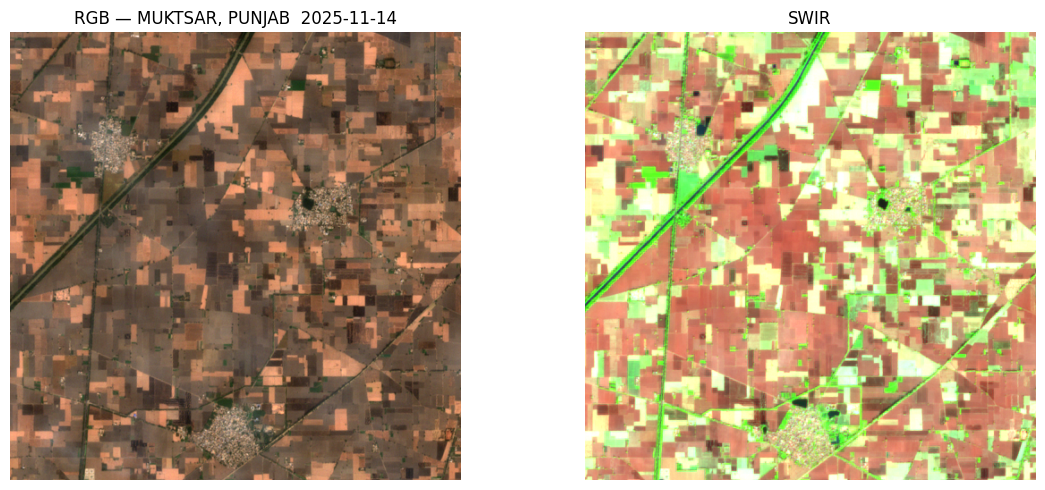

Ground truth:
{
  "burn_detected": true,
  "burn_severity": "moderate",
  "burn_fraction_estimate": 0.25,
  "burn_freshness": "recent",
  "active_smoke_visible": false,
  "vegetation_phase": "post_harvest",
  "image_quality_limited": false,
  "notes": "Post-harvest landscape with mostly harvested stubble fields. Dark brownish-red burn scars with rectangular field boundaries visible in SWIR, affecting ~22% of visible cropland."
}

Model output:
system
You are an expert in analyzing Sentinel-2 satellite imagery for crop residue burning detection in northern India. You analyze pairs of RGB and SWIR composites of 5km tiles and produce structured JSON assessments.
user
The following two images show the same 5km × 5km tile of agricultural land at the same date.

Image 1 is the RGB composite (B4-B3-B2, natural color).
Image 2 is the SWIR composite (B12-B8-B4 false color), which highlights vegetation moisture, burn scars, and active fires.

In the SWIR composite:
  - Bright green = healthy sta

In [13]:
model.eval()
import random

# Pick a burn sample for a visible check
idx = random.choice([i for i, x in enumerate(test_ds["burn_detected"]) if x])
sample = test_ds[idx]

msgs = [
    {"role": "system", "content": SYSTEM_PROMPT},
    {"role": "user", "content": [
        {"type": "image", "image": sample["rgb_image"]},
        {"type": "image", "image": sample["swir_image"]},
        {"type": "text",  "text": USER_PROMPT},
    ]},
]
inputs = processor.apply_chat_template(
    msgs, add_generation_prompt=True,
    return_tensors="pt", return_dict=True, tokenize=True,
).to(model.device)

with torch.no_grad():
    out = model.generate(**inputs, max_new_tokens=256, do_sample=False)

raw = processor.batch_decode(out, skip_special_tokens=True)[0]
response = raw.split("<|im_start|>assistant")[-1].strip() if "<|im_start|>assistant" in raw else raw

# Show images + outputs side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(sample["rgb_image"])
axes[0].set_title(f"RGB — {sample['district']}, {sample['state']}  {sample['date']}")
axes[0].axis("off")
axes[1].imshow(sample["swir_image"])
axes[1].set_title("SWIR")
axes[1].axis("off")
plt.tight_layout()
plt.show()

print("Ground truth:")
print(json.dumps(json.loads(sample["annotation_json"]), indent=2))
print("\nModel output:")
print(response)

In [14]:
for name, param in model.named_parameters():                                                                                                                
      if param.requires_grad:
          print(name)